# Project HF

This project is organised in different phase. Here are the final objectives of those phases:
- Phase 1: Dual IQ acquisition from the Pluto SDR using python
- Phase 2: Compute the angle from wich the signal comes from

We use a Pluto SDR to receive on two port, allowing to compute a phase difference and an ESP32 to emit. We connect antennas to both.

---

## The maths
Of course, this project will require some maths. The first one is a fromula to comute the difference in phase. We use this formula:
$$\phi$$

The next formula used allow us to compute the angle, from the phase difference and the distance between the two antennas.
$$\theta$$

In [5]:
SEUIL = 20 # dB

def compute_phase_difference(rx0, rx1):
    p = np.abs(rx0)**2 + np.abs(rx1)**2
    mask = p > SEUIL**2

    if np.sum(mask) == 0:
        return np.nan  # No valid samples, return NaN phase difference

    rx0 = rx0[mask]
    rx1 = rx1[mask]

    cross = np.sum(rx0 * np.conj(rx1))
    phi = np.degrees(np.angle(cross))
    return phi



def compute_angle(dp):
    dp = np.radians(dp)
    for n in range(10):
            theta = np.acos((dp-n*2*np.pi)/(2*np.pi*ANTENNAS_DISTANCE/WAVE_LENGTH))
            if not np.isnan(theta):
                return np.degrees(theta)
            
            print(f"N={n} is not a good candidate")
            print(f"Trying for N={-n}")

            n = -n
            theta = np.acos((dp-n*2*np.pi)/(2*np.pi*ANTENNAS_DISTANCE/WAVE_LENGTH))
            
            if not np.isnan(theta):
                return np.degrees(theta)

            print(f"N={-n} is not a good candidate")

    return 0

---

## Configuring

Before anything, we first need to configure our SDR.
We use the adi python library to do so, with its **ad9361**, not the Pluto one, which does not let us interface both antennas.
We juste need to configure some things, such as the sample rate, center frequency and we can proceed to record using the ```sdr.rx()``` method, which returns 2 lists in one, corresponding to the signal received by its repsecting antennas. For now, we just use it to empty the buffer

In [6]:
import numpy as np
import adi
import matplotlib.pyplot as plt


SAMPLE_RATE = 1e6 # Hz
CENTER_FREQUENCY = 2.432e9 # Hz
NUM_SAMPS = 100000 # number of samples per call to rx()
WAVE_LENGTH = 3*10**8/CENTER_FREQUENCY

ANTENNAS_DISTANCE = WAVE_LENGTH/2 #m

sdr = adi.ad9361("ip:192.168.2.1")
sdr.rx_enabled_channels = [0, 1] # active RX0 et RX1
sdr.sample_rate = int(SAMPLE_RATE)

# Config Rx
sdr.rx_lo = int(CENTER_FREQUENCY)
sdr.rx_rf_bandwidth = int(SAMPLE_RATE)
sdr.rx_buffer_size = NUM_SAMPS
sdr.gain_control_mode_chan0 = 'manual'
sdr.rx_hardwaregain_chan0 = 0.0 # dB
sdr.gain_control_mode_chan1 = 'manual'
sdr.rx_hardwaregain_chan1 = 0.0 # dB

# Clear buffer just to be safe
for i in range (0, 10):
    raw_data = sdr.rx()

ERROR: READ LINE: -104
ERROR: Unable to send command: Broken pipe (32)


---

## Spectrogram

Once the SDR is properly configured, we can observe the spectrogram of what it can see. It allows us to see what is on the bandwidth we work on and see if we can detect the ESP.

In [11]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import numpy as np

try:
    while True:
        raw_data = sdr.rx()  # List/array: [RX0 samples, RX1 samples]
        rx0 = np.asarray(raw_data[0], dtype=np.complex64)
        rx1 = np.asarray(raw_data[1], dtype=np.complex64)

        # FFT of complex IQ samples (not rfft)
        fft0 = np.fft.fftshift(np.fft.fft(rx0))
        fft1 = np.fft.fftshift(np.fft.fft(rx1))
        f = np.fft.fftshift(np.fft.fftfreq(len(rx0), d=1/SAMPLE_RATE))

        clear_output(wait=True)
        plt.figure(figsize=(10, 6))
        plt.plot(f, 20 * np.log10(np.abs(fft0) + np.finfo(float).eps), label='RX0')
        plt.plot(f, 20 * np.log10(np.abs(fft1) + np.finfo(float).eps), label='RX1')
        plt.title('Spectrum')
        plt.xlabel('Frequency (Hz)')
        plt.ylabel('Magnitude (dB)')
        plt.legend()
        plt.grid(True)
        plt.show()

except KeyboardInterrupt:
    print("Exiting...")

Exiting...


---

## Calibrating

Once the SDR is configured to receive on both its antennas, we can proceed to the calibration step. We need to make a calibration to find the impedance of the two paths of our antennas, as they might simply not be the same length for instance.

### Direct Calibration

We plug in the esp directly, through an **attenuator** and a **divider**.
The same signal is thus sent to both antennas and we can calculate $\phi_0$. It represents the phase difference of the perpendicular, when the esp is perfectly in front of the SDR, when the signal arrives exactly at the same time to the two antennas.

Mean phase difference between RX0 and RX1: 174.05 degrees


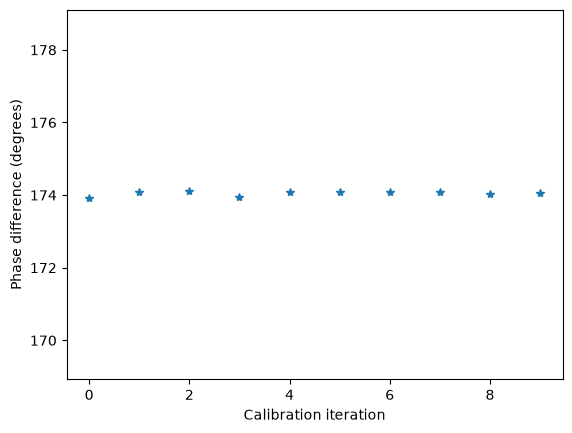

In [12]:
from time import sleep

N_CALIBRATIONS = 10

phis = []

for _ in range(N_CALIBRATIONS):

    # Receive samples
    rx_samples = sdr.rx()
    rx0 = rx_samples[0] # RX0
    rx1 = rx_samples[1] # RX1

    phi = compute_phase_difference(rx0, rx1)
    
    if phi is np.nan:
        raise ValueError("No valid samples received. Please ensure you are directly connected to ESP.")

    phis.append(phi)
    sleep(0.1)

print(f"Mean phase difference between RX0 and RX1: {np.mean(phis):.2f} degrees")
plt.plot(phis, "*")
plt.xlabel("Calibration iteration")
plt.ylabel("Phase difference (degrees)")
plt.ylim([min(phis)-5, max(phis)+5])
phi_0 = np.mean(phis)

### SOLT Calibration (more like SL)
Another way we can use to calibrate our system is by using the SLOP method: Short, Open, Load, Through. We have the material only to calibrate for Short, Open, Load. However, the Pluto SDR may not be able to stand the return current from an open circuit, so we can only use Short and Load calibration.

In [ ]:
# Short circuit calibration


---

# Meauring

We can now unplug the divider and plus in the antennas. We the proceeds to take measure.

In [13]:
N_MEASURES = 10

# Clear buffer just to be safe
for i in range (0, 10):
    raw_data = sdr.rx()

measures = []

for _ in range(10):
    # Receive samples
    rx_samples = sdr.rx()
    measures.append(rx_samples)

---

# Interpreting

Once we have the two signals, we can then do some math and find the phase of eache point, for each signal. We can then make some plot and try to find our signal and the difference in phase between the twos.

Mean delta phi = 174.09314892886997°


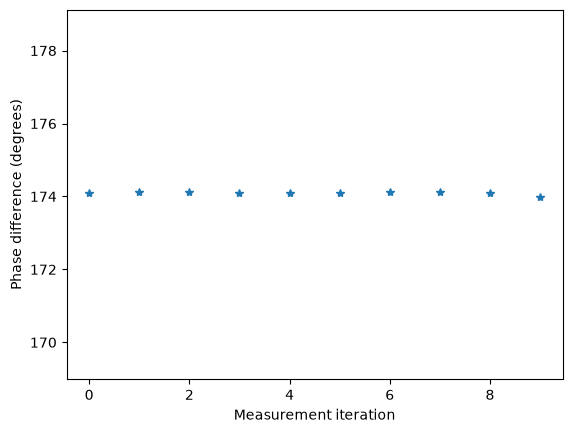

In [14]:
phis = []

for measure in measures:
    phi = compute_phase_difference(measure[0], measure[1])
    phis.append(phi)


print(f"Mean delta phi = {np.mean(phis)}°")

plt.plot(phis, "*")
plt.xlabel("Measurement iteration")
plt.ylabel("Phase difference (degrees)")
plt.ylim([min(phis)-5, max(phis)+5])
plt.show()

---

# Direct

Small piece of code to see phi in continue

Arrêt.


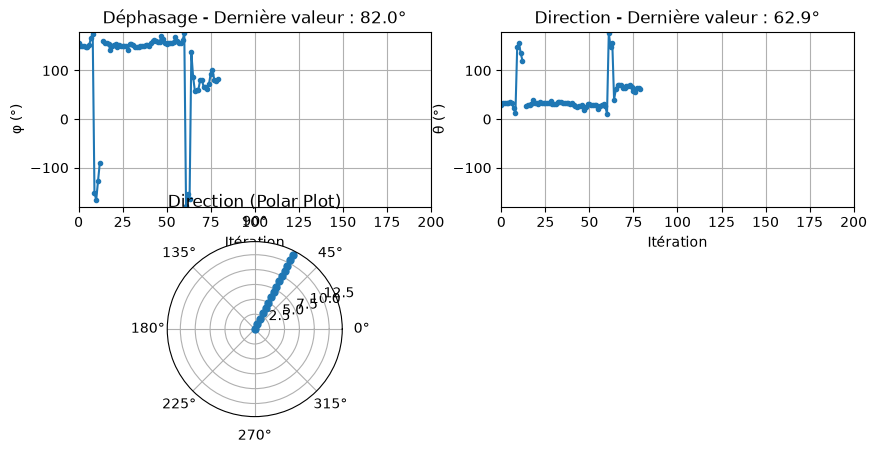

In [17]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

N_POINTS = 200

phis = []
thetas = []

if phi_0 is None:
    print("Calibration phase difference (phi_0) is not set. Please run the calibration step first.")
    print("Using default value of phi_0 = -165.5 degrees for demonstration purposes.")
    phi_0 = -172.61

print(f"Using calibration phase difference (phi_0) = {phi_0:.2f} degrees")

try:
    while True:
        rx_samples = sdr.rx()
        rx0 = rx_samples[0]
        rx1 = rx_samples[1]

        phi = compute_phase_difference(rx0, rx1)

        if phi is np.nan:
            theta = np.nan  # Assign NaN to thetas if no valid samples are received
        else:            
            phi = phi - phi_0  # Subtract the calibration phase difference
            phi = (phi + 180) % 360 - 180  # Wrap phi to [-180, 180]
            theta = compute_angle(phi)-90

        phis.append(phi)
        thetas.append(theta)

        phis = phis[-N_POINTS:]  # Keep only the last N_POINTS values
        thetas = thetas[-N_POINTS:]  # Keep only the last N_POINTS values

        clear_output(wait=True)
        plt.figure(figsize=(10, 5))
        plt.subplot(2, 2, 1)
        plt.plot(phis, '.-')
        plt.ylim(-180, 180)
        plt.xlim(0, N_POINTS)
        plt.xlabel("Itération")
        plt.ylabel("φ (°)")
        plt.title(f"Déphasage - Dernière valeur : {phi:.1f}°")
        plt.grid(True)

        plt.subplot(2, 2, 2)
        plt.plot(thetas, '.-')
        plt.ylim(-180, 180)
        plt.xlim(0, N_POINTS)
        plt.xlabel("Itération")
        plt.ylabel("θ (°)")
        plt.title(f"Direction - Dernière valeur : {theta:.1f}°")
        plt.grid(True)

        plt.subplot(2, 2, 3, projection='polar')
        plt.plot(15*[np.radians(thetas[-1])], [i for i in range(0,15)], 'o', markersize=5)
        plt.title("Direction (Polar Plot)")
        plt.tight_layout()
        plt.show()

except KeyboardInterrupt:
    print("Arrêt.")